# Forward pass e backpropagation

Este notebook implementa em python e usando NumPy, uma rede neural para **classificar as três espécies do conjunto Iris**. 

A rede tem duas camadas escondidas e arquitetura `4 -> 4 -> 4 -> 3`.



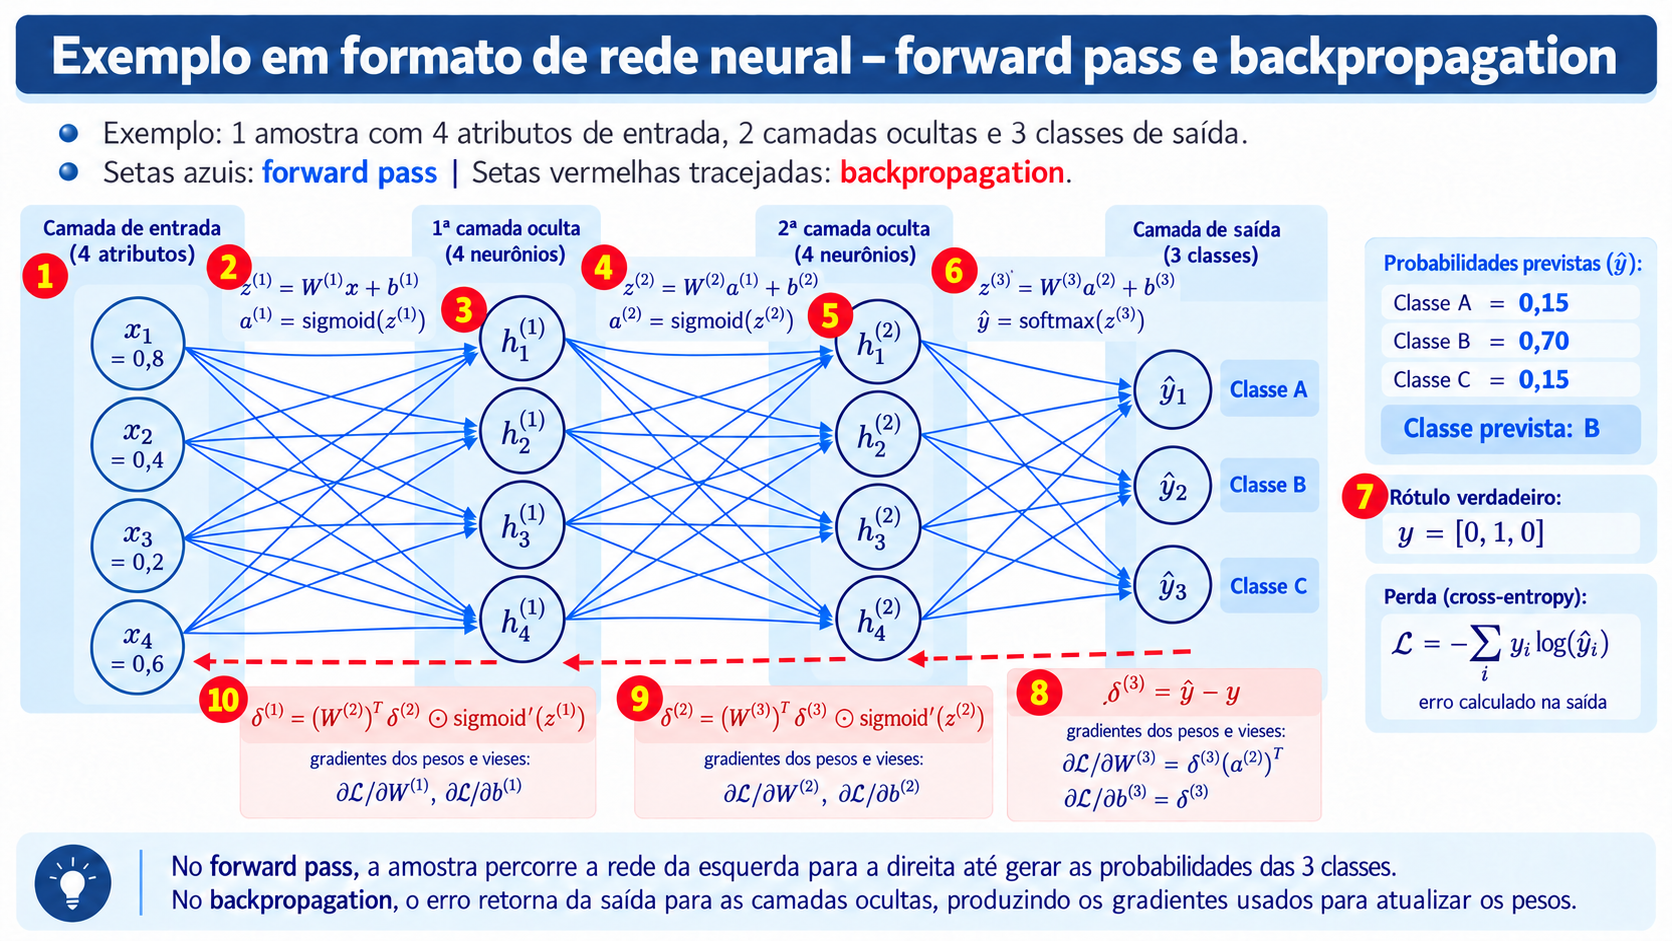

## 1. Dados

Cada flor possui quatro medidas e pertence a uma de três classes. O conjunto é dividido de forma estratificada em 80% para treinamento e 20% para teste, preservando a proporção das classes. A padronização usa apenas a média e o desvio-padrão do treinamento.

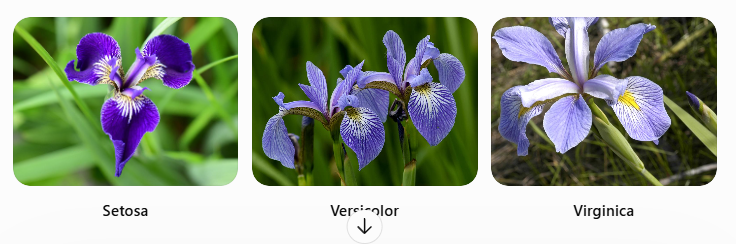

In [61]:
import csv

import numpy as np

np.set_printoptions(precision=5, suppress=True)

with open('iris_dataset.csv', encoding='utf-8', newline='') as arquivo:
    flores = list(csv.DictReader(arquivo))

todas_entradas = np.array([
    [
        float(flor['sepal.length']),
        float(flor['sepal.width']),
        float(flor['petal.length']),
        float(flor['petal.width']),
    ]
    for flor in flores
])

#print('Todas entradas', todas_entradas)

# [0,0,1]


nomes_classes = sorted({flor['variety'] for flor in flores})
#print('classes: ', nomes_classes)

classe_para_indice = {nome: indice for indice, nome in enumerate(nomes_classes)}
todas_classes = np.array([
    classe_para_indice[flor['variety']] for flor in flores
])

#print('todas classes', todas_classes)

todas_saidas_esperadas = np.eye(3)[todas_classes]

#print('todas saidas esperadas', todas_saidas_esperadas)

gerador_divisao = np.random.default_rng(42)
i_treino = []
i_teste = []

for i in range(3):
    i = np.flatnonzero(todas_classes == i)
    gerador_divisao.shuffle(i)
    qt_treino = int(0.8 * len(i))
    i_treino.extend(i[:qt_treino])
    i_teste.extend(i[qt_treino:])

i_treino = np.array(i_treino)
i_teste = np.array(i_teste)
gerador_divisao.shuffle(i_treino)
gerador_divisao.shuffle(i_teste)

treino = todas_entradas[i_treino]
saidas_esperadas_treino = todas_saidas_esperadas[i_treino]
classes_treino = todas_classes[i_treino]
entradas_teste = todas_entradas[i_teste]
saidas_esperadas_teste = todas_saidas_esperadas[i_teste]
classes_teste = todas_classes[i_teste]

# As estatísticas do teste não participam do treinamento.
media_atributos = treino.mean(axis=0)
desvio_padrao_atributos = treino.std(axis=0)
treino = (
    treino - media_atributos
) / desvio_padrao_atributos
entradas_teste = (
    entradas_teste - media_atributos
) / desvio_padrao_atributos

print('Entradas de treinamento:', treino.shape)
print('Entradas de teste:', entradas_teste.shape)
print('Exemplos por classe no treinamento:', np.bincount(classes_treino))
print('Exemplos por classe no teste:', np.bincount(classes_teste))
print('Classes:', nomes_classes)
print('Primeira entrada de treinamento padronizada:', treino[0])
print('Primeira saída esperada:', saidas_esperadas_treino[0])

Entradas de treinamento: (120, 4)
Entradas de teste: (30, 4)
Exemplos por classe no treinamento: [40 40 40]
Exemplos por classe no teste: [10 10 10]
Classes: ['Setosa', 'Versicolor', 'Virginica']
Primeira entrada de treinamento padronizada: [0.52293 0.53151 1.25764 1.70982]
Primeira saída esperada: [0. 0. 1.]


## 2. Arquitetura e funções de ativação

A rede possui três camadas de pesos:

1. quatro entradas para dois neurônios escondidos;
2. quatro ativações para dois neurônios escondidos;
3. quatro ativações para três classes de saída.

As duas camadas escondidas usam a sigmoide. A saída usa softmax, que produz probabilidades positivas cuja soma é um.

In [32]:
def sigmoide(valor):
    return 1.0 / (1.0 + np.exp(-valor))

# a'(x) = a(x) * (1.0 - a(x))
def derivada_sigmoide(ativacao):
    return ativacao * (1.0 - ativacao)


def softmax(valores):
    valores = valores - np.max(valores)
    exponenciais = np.exp(valores)
    return exponenciais / np.sum(exponenciais)


def inicializar_parametros(semente=42):
    gerador = np.random.default_rng(semente)
    tamanhos = [4, 4, 4, 3]
    pesos = []
    vieses = []

    for tamanho_anterior, tamanho_atual in zip(tamanhos[:-1], tamanhos[1:]):
        pesos.append(
            gerador.normal(
                0.0,
                1.0 / np.sqrt(tamanho_anterior),
                size=(tamanho_atual, tamanho_anterior),
            )
        )
        vieses.append(np.zeros((tamanho_atual, 1)))

    return pesos, vieses


pesos_iniciais, vieses_iniciais = inicializar_parametros()

for i, (peso, vies) in enumerate(zip(pesos_iniciais, vieses_iniciais)):
    print(f'\n### Camada {i+1}:')
    print(f'\nDimensões dos pesos: {peso.shape}')
    print(f'Valores dos pesos:\n{peso}')
    print(f'\nDimensões dos vieses: {vies.shape}')
    print(f'Valores dos vieses:\n{vies}')


### Camada 1:

Dimensões dos pesos: (4, 4)
Valores dos pesos:
[[ 0.15236 -0.51999  0.37523  0.47028]
 [-0.97552 -0.65109  0.06392 -0.15812]
 [-0.0084  -0.42652  0.4397   0.3889 ]
 [ 0.03302  0.56362  0.23375 -0.42965]]

Dimensões dos vieses: (4, 1)
Valores dos vieses:
[[0.]
 [0.]
 [0.]
 [0.]]

### Camada 2:

Dimensões dos pesos: (4, 4)
Valores dos pesos:
[[ 0.18438 -0.47944  0.43923 -0.02496]
 [-0.09243 -0.34046  0.61127 -0.07726]
 [-0.21416 -0.17607  0.26615  0.18272]
 [ 0.20637  0.21541  1.07082 -0.20321]]

Dimensões dos vieses: (4, 1)
Valores dos vieses:
[[0.]
 [0.]
 [0.]
 [0.]]

### Camada 3:

Dimensões dos pesos: (3, 4)
Valores dos pesos:
[[-0.25612 -0.40689  0.30799  0.56449]
 [-0.05697 -0.42008 -0.41224  0.3253 ]
 [ 0.37163  0.27158 -0.33275  0.11608]]

Dimensões dos vieses: (3, 1)
Valores dos vieses:
[[0.]
 [0.]
 [0.]]


## 3. Forward pass

Em cada camada escondida calculamos `z = W @ a_anterior + b` e depois `a = sigmoide(z)`. Na camada de saída, a ativação é `softmax(z)`.

As contas das três camadas estão escritas separadamente para que o caminho da entrada até a saída permaneça evidente.

In [66]:
def passagem_para_frente(entrada, pesos, vieses):
    ativacao_0 = np.asarray(entrada, dtype=float).reshape(4, 1)

    #print('ativacao_0', ativacao_0)

    combinacao_1 = pesos[0] @ ativacao_0 + vieses[0]
    #print('combinacao_1', combinacao_1)
    
    ativacao_1 = sigmoide(combinacao_1)

    #print('ativacao_1', ativacao_1)

    combinacao_2 = pesos[1] @ ativacao_1 + vieses[1]
    ativacao_2 = sigmoide(combinacao_2)

    combinacao_3 = pesos[2] @ ativacao_2 + vieses[2]
    probabilidades = softmax(combinacao_3)

    ativacoes = [ativacao_0, ativacao_1, ativacao_2, probabilidades]

    #print(ativacoes)
    combinacoes = [combinacao_1, combinacao_2, combinacao_3]
    return ativacoes, combinacoes


ativacoes_do_exemplo, combinacoes_do_exemplo = passagem_para_frente(
    treino[0], pesos_iniciais, vieses_iniciais
)

In [68]:
ativacoes_do_exemplo

[array([[0.52293],
        [0.53151],
        [1.25764],
        [1.70982]]),
 array([[0.74636],
        [0.25996],
        [0.72846],
        [0.46909]]),
 array([[0.57962],
        [0.56256],
        [0.51849],
        [0.70987]]),
 array([[0.36406],
        [0.23559],
        [0.40034]])]

In [42]:
ativacoes_do_exemplo

[array([[0.52293],
        [0.53151],
        [1.25764],
        [1.70982]]),
 array([[0.74636],
        [0.25996],
        [0.72846],
        [0.46909]]),
 array([[0.57962],
        [0.56256],
        [0.51849],
        [0.70987]]),
 array([[0.36406],
        [0.23559],
        [0.40034]])]

In [70]:
combinacoes_do_exemplo

[array([[ 1.07929],
        [-1.04616],
        [ 0.98683],
        [-0.1238 ]]),
 array([[0.32122],
        [0.25155],
        [0.07398],
        [0.89475]]),
 array([[ 0.18305],
        [-0.25216],
        [ 0.27805]])]

### Forward pass de uma flor, passo a passo

A célula seguinte mostra os operandos e o resultado de cada conta. Nas duas primeiras camadas, `a` é a sigmoide de `z`; na última, `a` contém as probabilidades produzidas pela softmax.

In [72]:
nomes_das_camadas = ['primeira escondida', 'segunda escondida', 'saída']

for indice, nome in enumerate(nomes_das_camadas):
    print(f'\nCAMADA {indice + 1}: {nome}')
    print(f'W{indice + 1} =\n{pesos_iniciais[indice]}')
    print(f'a{indice} =\n{ativacoes_do_exemplo[indice]}')
    produto = pesos_iniciais[indice] @ ativacoes_do_exemplo[indice]
    print(f'W{indice + 1} @ a{indice} =\n{produto}')
    print(f'b{indice + 1} =\n{vieses_iniciais[indice]}')
    print(f'z{indice + 1} = W{indice + 1} @ a{indice} + b{indice + 1} =\n{combinacoes_do_exemplo[indice]}')
    print(f'a{indice + 1} =\n{ativacoes_do_exemplo[indice + 1]}')

print('\nSoma das probabilidades:', ativacoes_do_exemplo[-1].sum())


CAMADA 1: primeira escondida
W1 =
[[ 0.15236 -0.51999  0.37523  0.47028]
 [-0.97552 -0.65109  0.06392 -0.15812]
 [-0.0084  -0.42652  0.4397   0.3889 ]
 [ 0.03302  0.56362  0.23375 -0.42965]]
a0 =
[[0.52293]
 [0.53151]
 [1.25764]
 [1.70982]]
W1 @ a0 =
[[ 1.07929]
 [-1.04616]
 [ 0.98683]
 [-0.1238 ]]
b1 =
[[0.]
 [0.]
 [0.]
 [0.]]
z1 = W1 @ a0 + b1 =
[[ 1.07929]
 [-1.04616]
 [ 0.98683]
 [-0.1238 ]]
a1 =
[[0.74636]
 [0.25996]
 [0.72846]
 [0.46909]]

CAMADA 2: segunda escondida
W2 =
[[ 0.18438 -0.47944  0.43923 -0.02496]
 [-0.09243 -0.34046  0.61127 -0.07726]
 [-0.21416 -0.17607  0.26615  0.18272]
 [ 0.20637  0.21541  1.07082 -0.20321]]
a1 =
[[0.74636]
 [0.25996]
 [0.72846]
 [0.46909]]
W2 @ a1 =
[[0.32122]
 [0.25155]
 [0.07398]
 [0.89475]]
b2 =
[[0.]
 [0.]
 [0.]
 [0.]]
z2 = W2 @ a1 + b2 =
[[0.32122]
 [0.25155]
 [0.07398]
 [0.89475]]
a2 =
[[0.57962]
 [0.56256]
 [0.51849]
 [0.70987]]

CAMADA 3: saída
W3 =
[[-0.25612 -0.40689  0.30799  0.56449]
 [-0.05697 -0.42008 -0.41224  0.3253 ]
 [ 0.3716

## 4. Verossimilhança e loss

In [74]:
def calcular_perda(probabilidades, saida_esperada):
    saida_esperada = np.asarray(saida_esperada, dtype=float).reshape(3, 1)
    probabilidades = np.clip(probabilidades, 1e-12, 1.0)
    return -float(np.sum(saida_esperada * np.log(probabilidades)))


probabilidades_do_exemplo = ativacoes_do_exemplo[-1]
saida_esperada_do_exemplo = saidas_esperadas_treino[0].reshape(3, 1)
indice_correto = classes_treino[0]
verossimilhanca_do_exemplo = probabilidades_do_exemplo[indice_correto, 0]
perda_do_exemplo = calcular_perda(
    probabilidades_do_exemplo, saida_esperada_do_exemplo
)

print('Saída esperada:', saida_esperada_do_exemplo.ravel())
print('Probabilidades:', probabilidades_do_exemplo.ravel())
print('Verossimilhança do exemplo:', verossimilhanca_do_exemplo)
print('Log-verossimilhança:', np.log(verossimilhanca_do_exemplo))
print('Perda = -log-verossimilhança:', perda_do_exemplo)

Saída esperada: [0. 0. 1.]
Probabilidades: [0.36406 0.23559 0.40034]
Verossimilhança do exemplo: 0.40034498909741756
Log-verossimilhança: -0.9154286308465133
Perda = -log-verossimilhança: 0.9154286308465133


## 5. Backpropagation

<pre>
    delta_n = variacao do que foi encontrado (probabilidades) em relacao ao que deveria ser (resultado espreado)
    gradiente_pesos_n = gratiente da perda em relação à combinação (delta) e o rseultado da ativacao tranposto
    gradiente_vies_n = assumindo a variacao como vies
</pre>

In [76]:
def retropropagacao(saida_esperada, pesos, ativacoes):
    saida_esperada = np.asarray(saida_esperada, dtype=float).reshape(3, 1)
    ativacao_0, ativacao_1, ativacao_2, probabilidades = ativacoes

    delta_3 = probabilidades - saida_esperada
    gradiente_pesos_3 = delta_3 @ ativacao_2.T
    gradiente_vies_3 = delta_3

    gradiente_ativacao_2 = pesos[2].T @ delta_3

    
    delta_2 = gradiente_ativacao_2 * derivada_sigmoide(ativacao_2)
    gradiente_pesos_2 = delta_2 @ ativacao_1.T
    gradiente_vies_2 = delta_2

    gradiente_ativacao_1 = pesos[1].T @ delta_2
    delta_1 = gradiente_ativacao_1 * derivada_sigmoide(ativacao_1)
    gradiente_pesos_1 = delta_1 @ ativacao_0.T
    gradiente_vies_1 = delta_1

    gradientes_pesos = [
        gradiente_pesos_1, gradiente_pesos_2, gradiente_pesos_3
    ]
    gradientes_vieses = [
        gradiente_vies_1, gradiente_vies_2, gradiente_vies_3
    ]
    deltas = [delta_1, delta_2, delta_3]
    return gradientes_pesos, gradientes_vieses, deltas


gradientes_pesos_exemplo, gradientes_vieses_exemplo, deltas_exemplo = (
    retropropagacao(
        saida_esperada_do_exemplo,
        pesos_iniciais,
        ativacoes_do_exemplo,
    )
)

In [78]:
gradientes_pesos_exemplo

[array([[-0.00078, -0.0008 , -0.00188, -0.00256],
        [ 0.00733,  0.00745,  0.01762,  0.02396],
        [-0.0037 , -0.00376, -0.00891, -0.01211],
        [ 0.00139,  0.00142,  0.00335,  0.00455]]),
 array([[-0.05992, -0.02087, -0.05849, -0.03766],
        [-0.0753 , -0.02623, -0.07349, -0.04732],
        [ 0.03998,  0.01392,  0.03902,  0.02513],
        [ 0.03267,  0.01138,  0.03189,  0.02053]]),
 array([[ 0.21102,  0.20481,  0.18876,  0.25844],
        [ 0.13656,  0.13253,  0.12215,  0.16724],
        [-0.34757, -0.33734, -0.31091, -0.42568]])]

In [53]:
gradientes_vieses_exemplo

[array([[-0.0015 ],
        [ 0.01401],
        [-0.00708],
        [ 0.00266]]),
 array([[-0.08029],
        [-0.10088],
        [ 0.05356],
        [ 0.04377]]),
 array([[ 0.36406],
        [ 0.23559],
        [-0.59966]])]

## 6. Treinamento

Forward e o backward das 120 flores do conjunto de treinamento (80%)
Calculo da média dos gradientes e atualizamos os parâmetros na direção que reduz a perda

In [80]:
def calcular_gradientes_medios(entradas, saidas_esperadas, pesos, vieses):
    soma_pesos = [np.zeros_like(peso) for peso in pesos]
    soma_vieses = [np.zeros_like(vies) for vies in vieses]
    soma_das_perdas = 0.0

    for entrada, saida_esperada in zip(entradas, saidas_esperadas):
        ativacoes, _ = passagem_para_frente(entrada, pesos, vieses)
        soma_das_perdas += calcular_perda(ativacoes[-1], saida_esperada)
        gradientes_pesos, gradientes_vieses, _ = retropropagacao(
            saida_esperada, pesos, ativacoes
        )

        for indice in range(3):
            soma_pesos[indice] += gradientes_pesos[indice]
            soma_vieses[indice] += gradientes_vieses[indice]

    quantidade = len(entradas)
    perda_media = soma_das_perdas / quantidade
    media_pesos = [gradiente / quantidade for gradiente in soma_pesos]
    media_vieses = [gradiente / quantidade for gradiente in soma_vieses]
    return perda_media, media_pesos, media_vieses


def atualizar_parametros(pesos, vieses, gradientes_pesos, gradientes_vieses, taxa):
    pesos = [
        peso - taxa * gradiente
        for peso, gradiente in zip(pesos, gradientes_pesos)
    ]
    vieses = [
        vies - taxa * gradiente
        for vies, gradiente in zip(vieses, gradientes_vieses)
    ]
    return pesos, vieses

In [88]:
pesos, vieses = inicializar_parametros()
taxa_aprendizagem = 1
quantidade_epocas = 1000
historico = []

for epoca in range(quantidade_epocas):
    perda_media, gradientes_pesos, gradientes_vieses = calcular_gradientes_medios(
        treino, saidas_esperadas_treino, pesos, vieses
    )

    if epoca % 300 == 0:
        historico.append((epoca, perda_media))

    pesos, vieses = atualizar_parametros(
        pesos,
        vieses,
        gradientes_pesos,
        gradientes_vieses,
        taxa_aprendizagem,
    )

perda_final, _, _ = calcular_gradientes_medios(
    treino, saidas_esperadas_treino, pesos, vieses
)
historico.append((quantidade_epocas, perda_final))

for epoca, perda in historico:
    print(f'Época {epoca:4d}: perda média = {perda:.6f}')


Época    0: perda média = 1.110182
Época  300: perda média = 0.083554
Época  600: perda média = 0.053485
Época  900: perda média = 0.047866
Época 1000: perda média = 0.046797


## 7. Resultado

A classe escolhida é a posição da maior probabilidade (argmax). A acurácia de treinamento mostra o ajuste aos dados usados para calcular os gradientes; a acurácia de teste mede o desempenho nos 20% de exemplos que permaneceram fora do treinamento.

In [92]:
def avaliar(entradas, classes_corretas, pesos, vieses):
    probabilidades = np.vstack([
        passagem_para_frente(entrada, pesos, vieses)[0][-1].ravel()
        for entrada in entradas
    ])

    #print(probabilidades)
    
    classes_preditas = np.argmax(probabilidades, axis=1)
    acuracia = np.mean(classes_preditas == classes_corretas)

    matriz_confusao = np.zeros((3, 3), dtype=int)
    for classe_correta, classe_predita in zip(
        classes_corretas, classes_preditas
    ):
        matriz_confusao[classe_correta, classe_predita] += 1

    return acuracia, matriz_confusao


acuracia_treino, matriz_confusao_treino = avaliar(
    treino, classes_treino, pesos, vieses
)
acuracia_teste, matriz_confusao_teste = avaliar(
    entradas_teste, classes_teste, pesos, vieses
)

print('Ordem das classes:', nomes_classes)
print(f'Acurácia de treinamento: {acuracia_treino:.2%}')
print('Matriz de confusão do treinamento:')
print(matriz_confusao_treino)
print(f'\nAcurácia de teste: {acuracia_teste:.2%}')
print('Matriz de confusão do teste:')
print(matriz_confusao_teste)

Ordem das classes: ['Setosa', 'Versicolor', 'Virginica']
Acurácia de treinamento: 98.33%
Matriz de confusão do treinamento:
[[40  0  0]
 [ 0 39  1]
 [ 0  1 39]]

Acurácia de teste: 96.67%
Matriz de confusão do teste:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]
